# SRGAN: AI Restoration of Historical Egyptian Monuments

**Goal:** turn low-resolution photos of Egyptian monuments (pyramids, temples, statues, reliefs) into sharper 4x high-resolution versions using **SRGAN** (Super-Resolution Generative Adversarial Network, Ledig et al. 2017), to support cultural-heritage documentation and preservation.

**How SRGAN works**

```
LR image (24x24 patch) --> Generator (16 residual blocks + PixelShuffle x2 x2) --> SR image (96x96)
                                                   |                                    |
                          Discriminator <----------+---- real HR image                  |
                          VGG19 features (perceptual / content loss) <-------------------+
```

| Loss | Purpose |
|---|---|
| **Content (VGG19 conv5_4)** | Makes the output look right to a pretrained vision network (textures, edges), not just pixel-close |
| **Adversarial** | The discriminator pushes outputs toward the look of real, sharp photographs |
| **Pixel L1 (small weight)** | Keeps the result faithful to the input, which matters for heritage imagery |

**Training recipe**
1. **Stage 1:** pre-train the generator alone with pixel MSE (this is *SRResNet*), which gives a stable starting point.
2. **Stage 2:** adversarial training (SRGAN) with the generator and discriminator.
3. **Evaluation:** compare bicubic vs SRResNet vs SRGAN with PSNR and SSIM, plus side-by-side visuals.

**Data:** any folder of Egyptian monument photos. On Kaggle, add one of the public Egypt landmarks/monuments image datasets as an input; on Colab, upload a zip. The notebook finds all images automatically. **Runtime: GPU required.**

## 1. Install and import

In [1]:
!pip install scikit-image --quiet

import os, io, math, time, copy, random, zipfile, warnings
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from skimage.metrics import structural_similarity

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms.functional as TF
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "NO GPU - enable one before training")

Device: cuda | Tesla T4


## 2. Configuration

Everything you may want to change is here. Set `QUICK_TEST = True` first to check that the whole notebook runs in a few minutes, then switch it off for real training.

In [2]:
# ---------- Data ----------
DATA_DIR   = "/kaggle/input" if Path("/kaggle/input").exists() else "data"   # folder with monument images (searched recursively)
MAX_IMAGES = 1200        # cap on training images (speeds up epochs)
MIN_SIDE   = 256         # ignore images whose shorter side is below this (they are not sharp enough to be HR targets)
MAX_SIDE   = 1024        # images are downscaled to this max side when loaded (sharper HR targets, faster loading)
VAL_IMAGES = 40

# ---------- Super-resolution ----------
SCALE     = 4
HR_SIZE   = 96           # HR training patch (LR patch = 24x24)
VAL_SIZE  = 256          # HR validation crop
P_DEGRADE = 0.5          # fraction of training LR images that also get blur + noise + JPEG (mimics old/low-quality photos)

# ---------- Training ----------
BATCH_SIZE      = 16
CROPS_PER_IMAGE = 6      # random crops drawn from each image per epoch
PRETRAIN_EPOCHS = 10     # stage 1 (SRResNet, pixel MSE)
GAN_EPOCHS      = 20     # stage 2 (SRGAN)
LR_G = LR_D = 1e-4
VGG_W, ADV_W, PIXEL_W = 0.006, 1e-3, 0.1   # loss weights (PIXEL_W is the "stay faithful to the input" knob)
REAL_LABEL = 0.9         # one-sided label smoothing for the discriminator
SHOW_EVERY = 5

QUICK_TEST = False
if QUICK_TEST:
    MAX_IMAGES, CROPS_PER_IMAGE, PRETRAIN_EPOCHS, GAN_EPOCHS, SHOW_EVERY = 100, 2, 2, 2, 1

OUT_DIR = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)
print("Config OK")

Config OK


## 3. Find the images

The cell searches `DATA_DIR` recursively for images. If none are found on Colab it asks you to upload a **zip** of monument photos. To pull a Kaggle dataset on Colab instead, set `KAGGLE_SLUG` (for example `"owner/dataset-name"`) and have your Kaggle credentials configured.

> **Tip:** some exported datasets contain augmented copies of the same photo. Near-duplicates across train and validation inflate the scores, so prefer the original, un-augmented images when you can.

Found 3842 image files under /kaggle/input


Checking sizes:   0%|          | 0/3842 [00:00<?, ?it/s]

Usable: 1240 | train 1200 | val 40


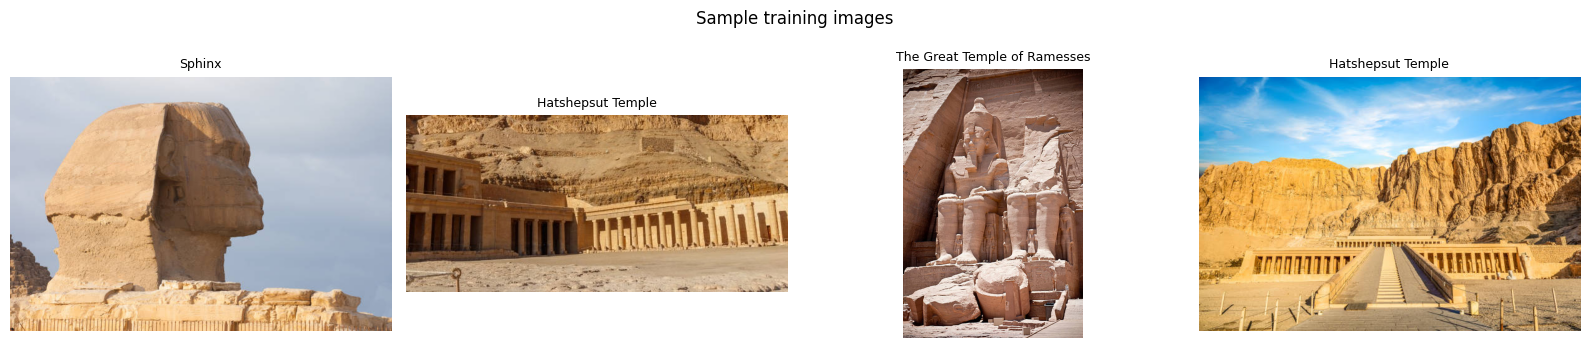

In [18]:
KAGGLE_SLUG = None   # e.g. "owner/egypt-monuments-dataset" (Colab + Kaggle credentials needed)
EXTS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

def list_images(root):
    out = []
    for dp, _, fns in os.walk(root):
        for fn in fns:
            if Path(fn).suffix.lower() in EXTS:
                out.append(os.path.join(dp, fn))
    return out

paths = list_images(DATA_DIR) if Path(DATA_DIR).exists() else []

if not paths and KAGGLE_SLUG:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "kagglehub", "-q"])
    import kagglehub
    DATA_DIR = kagglehub.dataset_download(KAGGLE_SLUG)
    paths = list_images(DATA_DIR)

if not paths:
    try:
        from google.colab import files
        print("Upload a .zip of Egyptian monument images...")
        up = files.upload()
        Path("data").mkdir(exist_ok=True)
        for name in up:
            if name.lower().endswith(".zip"):
                with zipfile.ZipFile(name) as zf: zf.extractall("data")
        DATA_DIR = "data"; paths = list_images(DATA_DIR)
    except ImportError:
        pass

assert paths, "No images found. Set DATA_DIR to a folder of images (or KAGGLE_SLUG / upload a zip on Colab)."
print(f"Found {len(paths)} image files under {DATA_DIR}")

good = []
for p in tqdm(paths, desc="Checking sizes"):
    try:
        with Image.open(p) as im:
            if min(im.size) >= MIN_SIDE: good.append(p)
    except Exception:
        pass
random.Random(SEED).shuffle(good)
good = good[:MAX_IMAGES + VAL_IMAGES]
assert len(good) > VAL_IMAGES + 10, f"Only {len(good)} usable images (min side {MIN_SIDE}px). Lower MIN_SIDE or add more data."

val_paths, train_paths = good[:VAL_IMAGES], good[VAL_IMAGES:]
print(f"Usable: {len(good)} | train {len(train_paths)} | val {len(val_paths)}")

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, p in zip(axes, train_paths[:4]):
    ax.imshow(Image.open(p).convert("RGB")); ax.set_title(Path(p).parent.name[:28], fontsize=9); ax.axis("off")
plt.suptitle("Sample training images"); plt.tight_layout(); plt.show()

## 4. Datasets: creating LR/HR pairs on the fly

SRGAN is trained **self-supervised**: we take a sharp photo as the target (HR), shrink it 4x to make the input (LR), and teach the network to undo that.

- **Bicubic** downsampling is the standard benchmark setting.
- With probability `P_DEGRADE` we also add **blur, sensor noise and JPEG compression** to the LR image. Real historical or web photos have these flaws, and a model trained only on clean bicubic input tends to amplify them.

LR batch (16, 3, 24, 24) | HR batch (16, 3, 96, 96) | iterations per epoch: 450


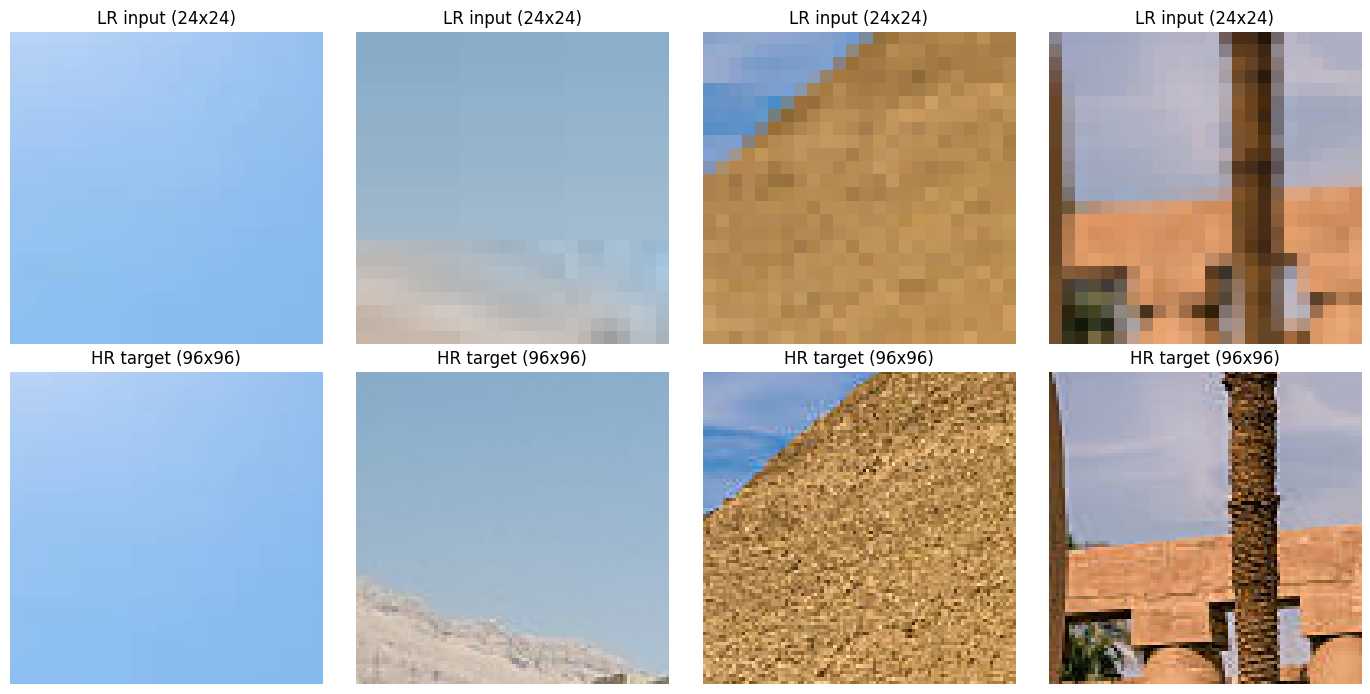

In [4]:
def load_image(path):
    img = Image.open(path)
    try:
        img.draft("RGB", (MAX_SIDE * 2, MAX_SIDE * 2))   # fast JPEG decode at reduced size
    except Exception:
        pass
    img = img.convert("RGB")
    if max(img.size) > MAX_SIDE:
        img.thumbnail((MAX_SIDE, MAX_SIDE), Image.LANCZOS)
    return img


def make_lr(hr_img, scale=SCALE, degrade=False):
    w, h = hr_img.size
    arr = np.array(hr_img)
    if degrade:
        arr = cv2.GaussianBlur(arr, (0, 0), random.uniform(0.3, 1.5))
    lr = Image.fromarray(arr).resize((w // scale, h // scale), Image.BICUBIC)
    if degrade:
        a = np.array(lr).astype(np.float32)
        a += np.random.normal(0, random.uniform(0, 6), a.shape)
        a = np.clip(a, 0, 255).astype(np.uint8)
        q = random.randint(40, 95)
        ok, enc = cv2.imencode(".jpg", np.ascontiguousarray(a[:, :, ::-1]), [cv2.IMWRITE_JPEG_QUALITY, q])
        a = cv2.imdecode(enc, cv2.IMREAD_COLOR)[:, :, ::-1]
        lr = Image.fromarray(np.ascontiguousarray(a))
    return lr


def ensure_min(img, size):
    w, h = img.size
    if min(w, h) < size:
        s = size / min(w, h)
        img = img.resize((math.ceil(w * s), math.ceil(h * s)), Image.BICUBIC)
    return img


def to_tensor_m11(img):          # PIL -> float tensor in [-1, 1]
    return TF.to_tensor(img) * 2 - 1


class SRTrainSet(Dataset):
    def __init__(self, paths, hr_size=HR_SIZE, repeat=CROPS_PER_IMAGE, p_degrade=P_DEGRADE):
        self.paths, self.hr, self.repeat, self.p = paths, hr_size, repeat, p_degrade
    def __len__(self):
        return len(self.paths) * self.repeat
    def __getitem__(self, i):
        img = ensure_min(load_image(self.paths[i % len(self.paths)]), self.hr)
        w, h = img.size
        x, y = random.randint(0, w - self.hr), random.randint(0, h - self.hr)
        hr = img.crop((x, y, x + self.hr, y + self.hr))
        if random.random() < 0.5:
            hr = hr.transpose(Image.FLIP_LEFT_RIGHT)
        lr = make_lr(hr, degrade=random.random() < self.p)
        return to_tensor_m11(lr), to_tensor_m11(hr)


class SRValSet(Dataset):
    """Deterministic centre crops with clean bicubic LR (the standard benchmark setting)."""
    def __init__(self, paths, size=VAL_SIZE):
        self.paths, self.size = paths, size
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = ensure_min(load_image(self.paths[i]), self.size)
        w, h = img.size
        x, y = (w - self.size) // 2, (h - self.size) // 2
        hr = img.crop((x, y, x + self.size, y + self.size))
        return to_tensor_m11(make_lr(hr, degrade=False)), to_tensor_m11(hr)


NUM_WORKERS = min(4, os.cpu_count() or 2)
train_ds, val_ds = SRTrainSet(train_paths), SRValSet(val_paths)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
                          pin_memory=True, drop_last=True, persistent_workers=NUM_WORKERS > 0)
val_loader = DataLoader(val_ds, batch_size=8, shuffle=False, num_workers=0)

lr_b, hr_b = next(iter(train_loader))
print(f"LR batch {tuple(lr_b.shape)} | HR batch {tuple(hr_b.shape)} | iterations per epoch: {len(train_loader)}")

show = lambda t: ((t.clamp(-1, 1) + 1) / 2).permute(1, 2, 0).numpy()
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for k in range(4):
    axes[0, k].imshow(show(lr_b[k]), interpolation="nearest"); axes[0, k].set_title("LR input (24x24)")
    axes[1, k].imshow(show(hr_b[k])); axes[1, k].set_title("HR target (96x96)")
    axes[0, k].axis("off"); axes[1, k].axis("off")
plt.tight_layout(); plt.show()

## 5. Models

- **Generator:** 9x9 conv, then **16 residual blocks** (conv-BN-PReLU-conv-BN with a skip connection), a long skip connection, two **PixelShuffle** upsampling blocks (each 2x, so 4x total), and a final 9x9 conv with `tanh`. Upsampling happens at the end, so most computation runs at low resolution.
- **Discriminator:** 8 convolution layers with growing channels (64 to 512) and strided downsampling, then two dense layers producing a real/fake logit.
- **VGG19 feature extractor:** frozen, pretrained on ImageNet. Features from `conv5_4` give the perceptual (content) loss.

In [5]:
class ResBlock(nn.Module):
    def __init__(self, ch=64):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(ch, ch, 3, 1, 1), nn.BatchNorm2d(ch), nn.PReLU(),
            nn.Conv2d(ch, ch, 3, 1, 1), nn.BatchNorm2d(ch),
        )
    def forward(self, x):
        return x + self.body(x)


class UpBlock(nn.Module):
    def __init__(self, ch=64):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(ch, ch * 4, 3, 1, 1), nn.PixelShuffle(2), nn.PReLU())
    def forward(self, x):
        return self.net(x)


class Generator(nn.Module):
    def __init__(self, n_res=16, ch=64, scale=SCALE):
        super().__init__()
        self.head = nn.Sequential(nn.Conv2d(3, ch, 9, 1, 4), nn.PReLU())
        self.res = nn.Sequential(*[ResBlock(ch) for _ in range(n_res)])
        self.mid = nn.Sequential(nn.Conv2d(ch, ch, 3, 1, 1), nn.BatchNorm2d(ch))
        self.up = nn.Sequential(*[UpBlock(ch) for _ in range(int(math.log2(scale)))])
        self.tail = nn.Conv2d(ch, 3, 9, 1, 4)
    def forward(self, x):
        x0 = self.head(x)
        x = self.mid(self.res(x0)) + x0
        return torch.tanh(self.tail(self.up(x)))


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        def blk(i, o, s):
            return [nn.Conv2d(i, o, 3, s, 1), nn.BatchNorm2d(o), nn.LeakyReLU(0.2, inplace=True)]
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, 3, 1, 1), nn.LeakyReLU(0.2, inplace=True),
            *blk(64, 64, 2), *blk(64, 128, 1), *blk(128, 128, 2),
            *blk(128, 256, 1), *blk(256, 256, 2), *blk(256, 512, 1), *blk(512, 512, 2),
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(6), nn.Flatten(),
            nn.Linear(512 * 36, 1024), nn.LeakyReLU(0.2, inplace=True), nn.Linear(1024, 1),
        )
    def forward(self, x):
        return self.classifier(self.features(x))


class VGGFeatures(nn.Module):
    """VGG19 up to conv5_4 (before the ReLU). Input in [-1, 1]."""
    def __init__(self):
        super().__init__()
        vgg = torchvision.models.vgg19(weights=torchvision.models.VGG19_Weights.IMAGENET1K_V1).features[:35].eval()
        for p in vgg.parameters():
            p.requires_grad_(False)
        self.vgg = vgg
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
    def forward(self, x):
        return self.vgg(((x + 1) / 2 - self.mean) / self.std)


G, D, vgg = Generator().to(DEVICE), Discriminator().to(DEVICE), VGGFeatures().to(DEVICE)
count = lambda m: sum(p.numel() for p in m.parameters() if p.requires_grad)
print(f"Generator params: {count(G):,} | Discriminator params: {count(D):,}")
with torch.no_grad():
    print("G output shape:", tuple(G(torch.randn(1, 3, 24, 24, device=DEVICE)).shape), "| D output shape:", tuple(D(torch.randn(2, 3, 96, 96, device=DEVICE)).shape))

Downloading: "https://download.pytorch.org/models/vgg19-dcbb9e9d.pth" to /root/.cache/torch/hub/checkpoints/vgg19-dcbb9e9d.pth


100%|██████████| 548M/548M [00:02<00:00, 241MB/s] 


Generator params: 1,549,462 | Discriminator params: 23,565,505
G output shape: (1, 3, 96, 96) | D output shape: (2, 1)


## 6. Metrics and tiled inference

- **PSNR / SSIM** measure pixel-level similarity to the real HR image (higher is better). 
- A GAN is trained to look realistic, not to minimise pixel error, so SRGAN often has **lower PSNR than SRResNet but looks sharper and more natural**. This is the well-known perception-distortion trade-off, so judge the results visually as well as numerically.
- **Tiled inference** lets us enhance large photos without running out of GPU memory: the image is processed in tiles with overlapping context that is discarded afterwards, so no seams appear.

In [6]:
def psnr(a, b):  # tensors in [0, 1]
    mse = F.mse_loss(a, b).item()
    return 99.0 if mse == 0 else 10 * math.log10(1.0 / mse)

def ssim(a, b):  # tensors in [0, 1], CHW
    return structural_similarity(a.permute(1, 2, 0).cpu().numpy(), b.permute(1, 2, 0).cpu().numpy(),
                                 channel_axis=2, data_range=1.0)

to01 = lambda t: (t.clamp(-1, 1) + 1) / 2


@torch.no_grad()
def evaluate(model, loader, bicubic=False):
    model.eval() if model is not None else None
    ps, ss = [], []
    for lr_, hr_ in loader:
        lr_, hr_ = lr_.to(DEVICE), hr_.to(DEVICE)
        sr = F.interpolate(lr_, scale_factor=SCALE, mode="bicubic", align_corners=False) if bicubic else model(lr_)
        for s, h in zip(to01(sr), to01(hr_)):
            ps.append(psnr(s, h)); ss.append(ssim(s, h))
    return float(np.mean(ps)), float(np.mean(ss))


@torch.no_grad()
def sr_image(model, img, tile=160, pad=16):
    """Upscale a PIL image 4x with overlapping tiles. Returns a PIL image."""
    model.eval()
    x = (TF.to_tensor(img.convert("RGB")) * 2 - 1).unsqueeze(0)
    _, _, h, w = x.shape
    pad = min(pad, h - 1, w - 1)
    xp = F.pad(x, (pad, pad, pad, pad), mode="reflect")
    out = torch.zeros(1, 3, h * SCALE, w * SCALE)
    for y0 in range(0, h, tile):
        for x0 in range(0, w, tile):
            y1, x1 = min(y0 + tile, h), min(x0 + tile, w)
            patch = xp[:, :, y0:y1 + 2 * pad, x0:x1 + 2 * pad].to(DEVICE)
            sr = model(patch).cpu()
            out[:, :, y0 * SCALE:y1 * SCALE, x0 * SCALE:x1 * SCALE] = \
                sr[:, :, pad * SCALE:(pad + y1 - y0) * SCALE, pad * SCALE:(pad + x1 - x0) * SCALE]
    return TF.to_pil_image(to01(out[0]))

## 7. Stage 1: pre-train the generator (SRResNet)

The generator is first trained alone with pixel-wise MSE. Starting the GAN game from a reasonable generator avoids the unstable early phase where the discriminator wins immediately.

In [7]:
opt_pre = torch.optim.Adam(G.parameters(), lr=LR_G, betas=(0.9, 0.999))
hist_pre = []
best_psnr, best_state = -1, None

print(f"{'Epoch':>5} {'MSE loss':>10} {'Val PSNR':>9} {'Val SSIM':>9}")
for epoch in range(1, PRETRAIN_EPOCHS + 1):
    G.train(); tot, n = 0.0, 0
    for lr_, hr_ in tqdm(train_loader, desc=f"Pretrain {epoch}/{PRETRAIN_EPOCHS}", leave=False):
        lr_, hr_ = lr_.to(DEVICE, non_blocking=True), hr_.to(DEVICE, non_blocking=True)
        loss = F.mse_loss(G(lr_), hr_)
        opt_pre.zero_grad(set_to_none=True); loss.backward(); opt_pre.step()
        tot += loss.item() * lr_.size(0); n += lr_.size(0)
    vp, vs = evaluate(G, val_loader)
    hist_pre.append(dict(epoch=epoch, loss=tot / n, psnr=vp, ssim=vs))
    if vp > best_psnr:
        best_psnr, best_state = vp, copy.deepcopy(G.state_dict())
    print(f"{epoch:>5} {tot / n:>10.5f} {vp:>9.2f} {vs:>9.4f}")

G.load_state_dict(best_state)                      # keep the best SRResNet
G_pre = copy.deepcopy(G).eval()                    # frozen copy for comparison later
torch.save(G_pre.state_dict(), OUT_DIR / "srresnet_generator.pth")
print(f"\nSRResNet ready (best val PSNR {best_psnr:.2f} dB)")

Epoch   MSE loss  Val PSNR  Val SSIM


Pretrain 1/10:   0%|          | 0/450 [00:00<?, ?it/s]

    1    0.04167     23.02    0.6061


Pretrain 2/10:   0%|          | 0/450 [00:00<?, ?it/s]

    2    0.02472     23.79    0.6468


Pretrain 3/10:   0%|          | 0/450 [00:00<?, ?it/s]

... (11 outputs left out)

Pretrain 9/10:   0%|          | 0/450 [00:00<?, ?it/s]

    9    0.02065     24.75    0.6912


Pretrain 10/10:   0%|          | 0/450 [00:00<?, ?it/s]

   10    0.02046     24.79    0.6951

SRResNet ready (best val PSNR 24.79 dB)


## 8. Stage 2: adversarial training (SRGAN)

Each iteration:
1. **Discriminator step:** learn to tell real HR patches (label 0.9, a little label smoothing) from generated ones (label 0).
2. **Generator step:** minimise `0.006 x VGG content loss + 0.001 x adversarial loss + 0.1 x L1 pixel loss`.

The learning rate drops 10x halfway through. Watch `D(real)` and `D(fake)`: if `D(fake)` stays near 0 and the generator loss climbs, the discriminator is winning; values hovering around 0.3 to 0.7 indicate a healthy balance.

In [8]:
bce = nn.BCEWithLogitsLoss()
opt_G = torch.optim.Adam(G.parameters(), lr=LR_G, betas=(0.9, 0.999))
opt_D = torch.optim.Adam(D.parameters(), lr=LR_D, betas=(0.9, 0.999))
milestones = [max(1, GAN_EPOCHS // 2)]
sch_G = torch.optim.lr_scheduler.MultiStepLR(opt_G, milestones, gamma=0.1)
sch_D = torch.optim.lr_scheduler.MultiStepLR(opt_D, milestones, gamma=0.1)

hist_gan = []
print(f"{'Ep':>3} {'D loss':>7} {'G loss':>7} {'VGG':>8} {'Adv':>6} {'D(real)':>8} {'D(fake)':>8} {'PSNR':>6} {'SSIM':>7}")

for epoch in range(1, GAN_EPOCHS + 1):
    G.train(); D.train()
    agg, n = defaultdict(float), 0
    for lr_, hr_ in tqdm(train_loader, desc=f"GAN {epoch}/{GAN_EPOCHS}", leave=False):
        lr_, hr_ = lr_.to(DEVICE, non_blocking=True), hr_.to(DEVICE, non_blocking=True)
        b = lr_.size(0)
        real_t = torch.full((b, 1), REAL_LABEL, device=DEVICE)
        fake_t = torch.zeros((b, 1), device=DEVICE)

        # ---- Discriminator ----
        with torch.no_grad():
            sr = G(lr_)
        d_real, d_fake = D(hr_), D(sr)
        d_loss = 0.5 * (bce(d_real, real_t) + bce(d_fake, fake_t))
        opt_D.zero_grad(set_to_none=True); d_loss.backward(); opt_D.step()

        # ---- Generator ----
        for p in D.parameters(): p.requires_grad_(False)
        sr = G(lr_)
        with torch.no_grad():
            f_hr = vgg(hr_)
        content = F.mse_loss(vgg(sr), f_hr)
        adv = bce(D(sr), torch.ones((b, 1), device=DEVICE))
        pix = F.l1_loss(sr, hr_)
        g_loss = VGG_W * content + ADV_W * adv + PIXEL_W * pix
        opt_G.zero_grad(set_to_none=True); g_loss.backward(); opt_G.step()
        for p in D.parameters(): p.requires_grad_(True)

        agg["d_loss"] += d_loss.item() * b; agg["g_loss"] += g_loss.item() * b
        agg["vgg"] += (VGG_W * content).item() * b; agg["adv"] += (ADV_W * adv).item() * b
        agg["d_real"] += torch.sigmoid(d_real).mean().item() * b; agg["d_fake"] += torch.sigmoid(d_fake).mean().item() * b
        n += b

    sch_G.step(); sch_D.step()
    vp, vs = evaluate(G, val_loader)
    row = {k: v / n for k, v in agg.items()}; row.update(epoch=epoch, psnr=vp, ssim=vs)
    hist_gan.append(row)
    print(f"{epoch:>3} {row['d_loss']:>7.3f} {row['g_loss']:>7.4f} {row['vgg']:>8.5f} {row['adv']:>6.4f} "
          f"{row['d_real']:>8.3f} {row['d_fake']:>8.3f} {vp:>6.2f} {vs:>7.4f}")

    torch.save({"G": G.state_dict(), "D": D.state_dict(), "epoch": epoch}, OUT_DIR / "srgan_last.pth")

torch.save(G.state_dict(), OUT_DIR / "srgan_generator.pth")
G_gan = copy.deepcopy(G).eval()
print("\nSRGAN training finished. Generator saved to", OUT_DIR / "srgan_generator.pth")

 Ep  D loss  G loss      VGG    Adv  D(real)  D(fake)   PSNR    SSIM


GAN 1/20:   0%|          | 0/450 [00:00<?, ?it/s]

  1   0.360  0.0636  0.04705 0.0045    0.765    0.127  20.46  0.4988


GAN 2/20:   0%|          | 0/450 [00:00<?, ?it/s]

  2   0.351  0.0603  0.04353 0.0042    0.773    0.124  20.90  0.5095


GAN 3/20:   0%|          | 0/450 [00:00<?, ?it/s]

... (31 outputs left out)

GAN 19/20:   0%|          | 0/450 [00:00<?, ?it/s]

 19   0.270  0.0552  0.03920 0.0043    0.819    0.079  21.52  0.5546


GAN 20/20:   0%|          | 0/450 [00:00<?, ?it/s]

 20   0.278  0.0541  0.03834 0.0041    0.814    0.083  21.46  0.5454

SRGAN training finished. Generator saved to outputs/srgan_generator.pth


## 9. Training curves

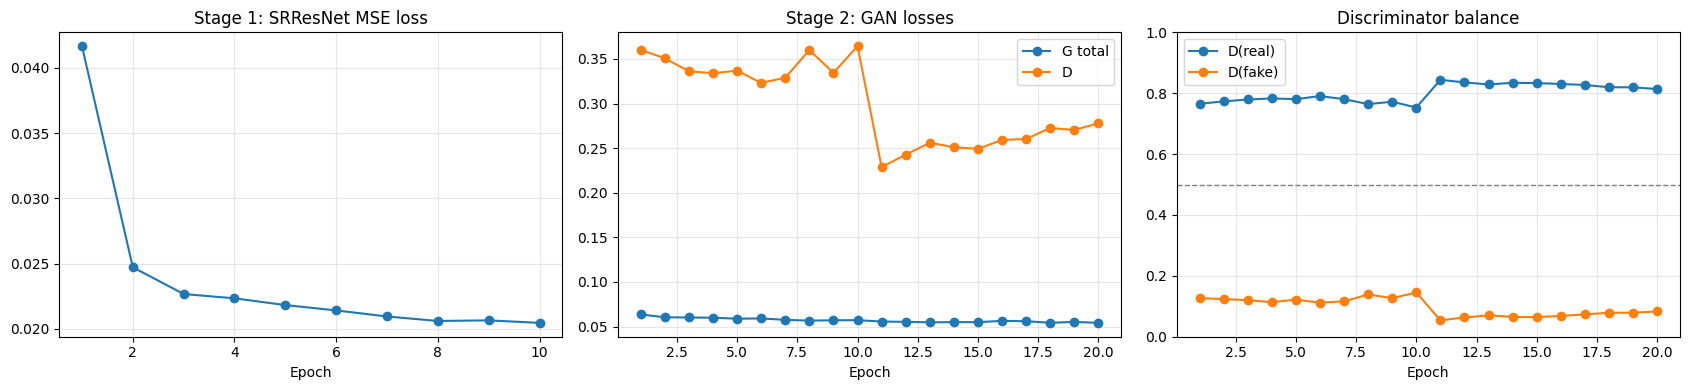

In [9]:
hp, hg = pd.DataFrame(hist_pre), pd.DataFrame(hist_gan)
fig, ax = plt.subplots(1, 3, figsize=(17, 4))

ax[0].plot(hp.epoch, hp.loss, "o-", color="tab:blue"); ax[0].set_title("Stage 1: SRResNet MSE loss")
ax[0].set_xlabel("Epoch")

ax[1].plot(hg.epoch, hg.g_loss, "o-", label="G total"); ax[1].plot(hg.epoch, hg.d_loss, "o-", label="D")
ax[1].set_title("Stage 2: GAN losses"); ax[1].set_xlabel("Epoch"); ax[1].legend()

ax[2].plot(hg.epoch, hg.d_real, "o-", label="D(real)"); ax[2].plot(hg.epoch, hg.d_fake, "o-", label="D(fake)")
ax[2].axhline(0.5, color="gray", ls="--", lw=1); ax[2].set_ylim(0, 1)
ax[2].set_title("Discriminator balance"); ax[2].set_xlabel("Epoch"); ax[2].legend()
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 10. Quantitative comparison

Bicubic interpolation is the classical baseline. All three are evaluated on the same held-out validation crops (clean 4x bicubic LR input).

In [10]:
rows = []
bp, bs = evaluate(None, val_loader, bicubic=True)
rows.append(("Bicubic (baseline)", bp, bs))
for name, m in [("SRResNet (stage 1)", G_pre), ("SRGAN (stage 2)", G_gan)]:
    p, s = evaluate(m, val_loader); rows.append((name, p, s))

table = pd.DataFrame(rows, columns=["Method", "PSNR (dB)", "SSIM"]).round(4)
table.to_csv(OUT_DIR / "metrics.csv", index=False)
display(table)
print("Reminder: SRGAN usually trades some PSNR for sharper, more realistic texture. Compare the images below, not only the numbers.")

,Method,PSNR (dB),SSIM
0,Bicubic (baseline),24.5316,0.6944
1,SRResNet (stage 1),24.7861,0.6951
2,SRGAN (stage 2),21.4566,0.5454


Reminder: SRGAN usually trades some PSNR for sharper, more realistic texture. Compare the images below, not only the numbers.


## 11. Visual comparison on held-out monument photos

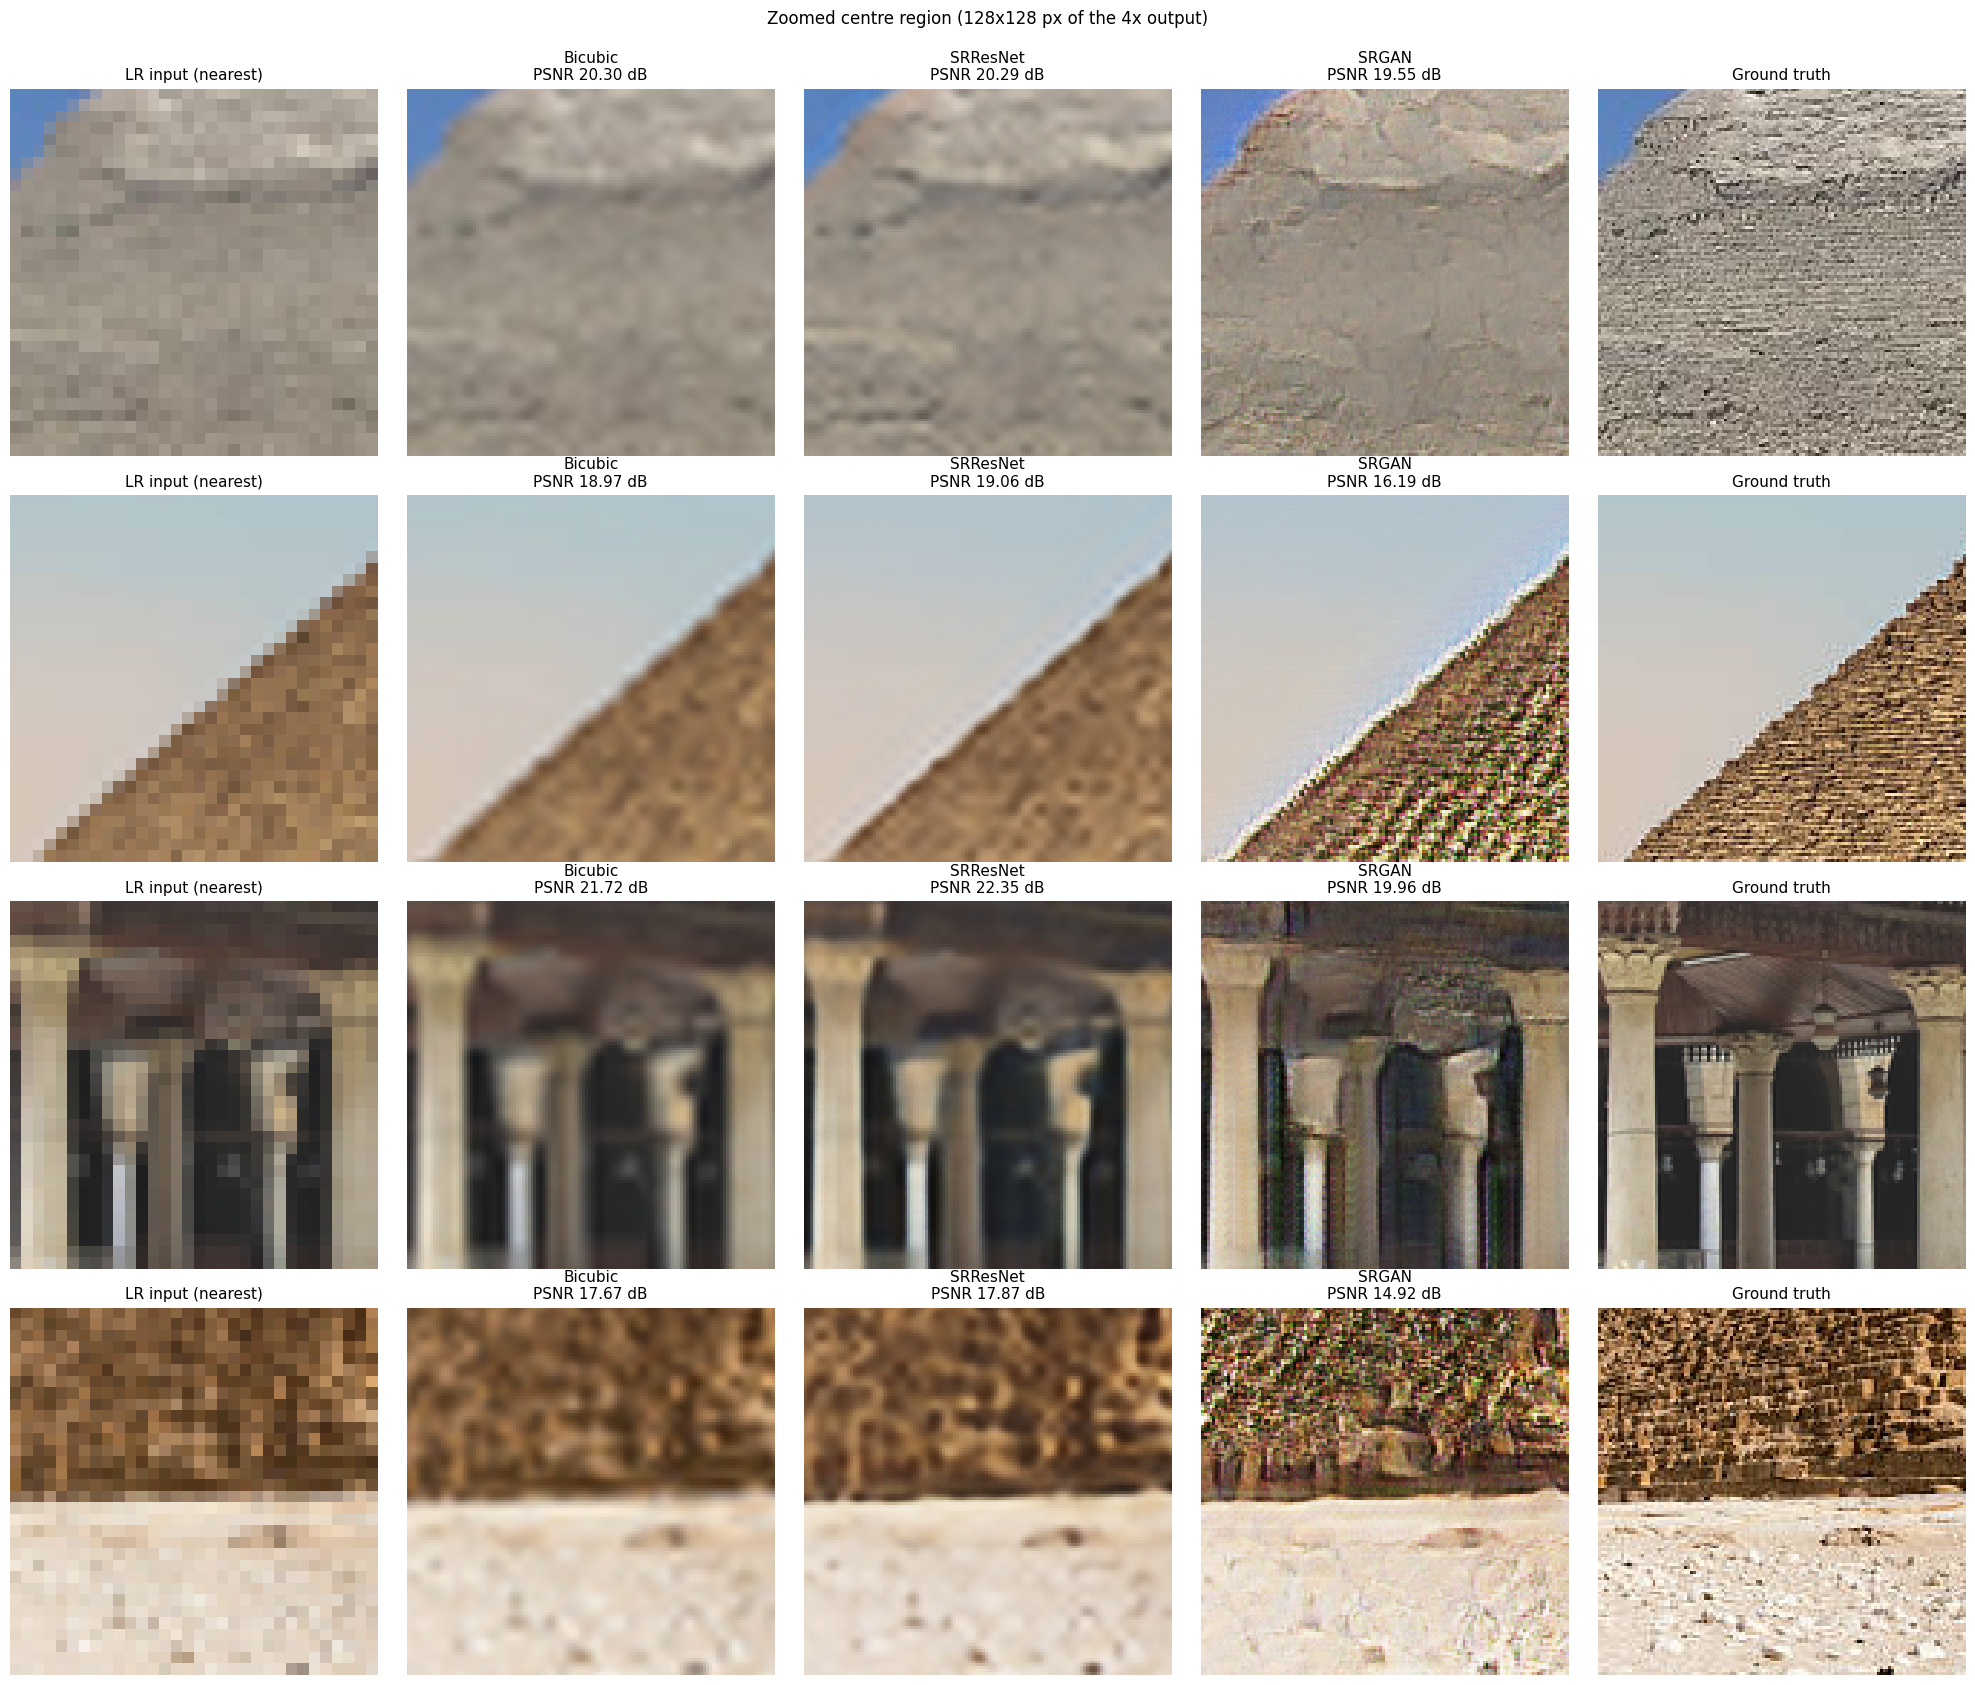

In [11]:
@torch.no_grad()
def compare(indices, zoom=128):
    cols = ["LR input (nearest)", "Bicubic", "SRResNet", "SRGAN", "Ground truth"]
    fig, axes = plt.subplots(len(indices), 5, figsize=(20, 4.2 * len(indices)))
    axes = np.atleast_2d(axes)
    for r, idx in enumerate(indices):
        lr_, hr_ = val_ds[idx]
        lr_b, hr_b = lr_.unsqueeze(0).to(DEVICE), hr_.unsqueeze(0).to(DEVICE)
        outs = [F.interpolate(lr_b, scale_factor=SCALE, mode="nearest"),
                F.interpolate(lr_b, scale_factor=SCALE, mode="bicubic", align_corners=False),
                G_pre(lr_b), G_gan(lr_b), hr_b]
        o = (VAL_SIZE - zoom) // 2
        for c, (name, t) in enumerate(zip(cols, outs)):
            t = to01(t[0])
            title = name if c in (0, 4) else f"{name}\nPSNR {psnr(t, to01(hr_b[0])):.2f} dB"
            axes[r, c].imshow(t[:, o:o + zoom, o:o + zoom].permute(1, 2, 0).cpu().numpy(), interpolation="nearest")
            axes[r, c].set_title(title, fontsize=11); axes[r, c].axis("off")
    plt.suptitle(f"Zoomed centre region ({zoom}x{zoom} px of the 4x output)", y=1.0)
    plt.tight_layout(); plt.show()

compare(list(range(min(4, len(val_ds)))))

## 12. Enhance your own low-resolution monument photos

Set `INPUT` to a single image or a folder (on Colab you can upload files when `INPUT = None`). Each photo is upscaled 4x with tiled inference and saved to `outputs/enhanced/`. The cell also displays a before/after comparison against plain bicubic upscaling.

In [13]:
import ipywidgets as widgets
uploader = widgets.FileUpload()
uploader

FileUpload(value=(), description='Upload')

In [4]:
INPUT = None            # e.g. "my_photos/" or "sphinx_lowres.jpg"; None = upload (Colab)
MODEL = G_gan           # G_gan (sharper, more detail) or G_pre (more conservative / faithful)

ENH_DIR = OUT_DIR / "enhanced"; ENH_DIR.mkdir(exist_ok=True)

if INPUT is None:
    try:
        from google.colab import files
        up = files.upload(); in_paths = list(up.keys())
    except ImportError:
        in_paths = []
elif Path(INPUT).is_dir():
    in_paths = list_images(INPUT)
else:
    in_paths = [INPUT]

for p in in_paths[:6]:
    img = Image.open(p).convert("RGB")
    sr = sr_image(MODEL, img)
    sr.save(ENH_DIR / (Path(p).stem + "_x4.png"))
    bic = img.resize((img.width * SCALE, img.height * SCALE), Image.BICUBIC)

    fig, ax = plt.subplots(1, 2, figsize=(14, 6))
    ax[0].imshow(bic); ax[0].set_title(f"Bicubic x4 ({bic.width}x{bic.height})"); ax[0].axis("off")
    ax[1].imshow(sr);  ax[1].set_title("SRGAN x4"); ax[1].axis("off")
    plt.tight_layout(); plt.show()

print(f"Enhanced {min(len(in_paths), 6)} image(s) -> {ENH_DIR}" if in_paths else "No input images given; skipped.")

NameError: name 'G_gan' is not defined

In [16]:
from google.colab import files
uploaded = files.upload()

KeyboardInterrupt: 

## 13. Save the results

`outputs/` contains the SRGAN and SRResNet generator weights, the last full checkpoint, the metrics table and any enhanced images. Download it before the session ends.

In [ ]:
import shutil
shutil.make_archive("srgan_egypt_outputs", "zip", OUT_DIR)
print("Packaged:", "srgan_egypt_outputs.zip")
for f in sorted(OUT_DIR.glob("*")):
    print(" -", f.name)

## Notes, limitations and responsible use

**Restoration is not documentation.** SRGAN *invents plausible detail*. Hieroglyph strokes, cartouches, paint traces or cracks in an enhanced image may not exist on the real monument. Use the output for visualisation, public engagement and as a starting point for restoration planning, never as evidence for epigraphic reading, dating or condition assessment, and always label enhanced images as AI-generated. Keep the original photograph with any published result.

**Why the generator can look "too clean":** if the training photos are modern and sharp, the model learns modern photographic texture. Adding degradations (`P_DEGRADE`) and, ideally, training on real archival photographs of the same sites improves fidelity to genuinely old material.

**Ideas to go further**
- Raise `PIXEL_W` for more faithful (less hallucinated) results, or lower it for more texture.
- Train longer and on more images; fine-tune on one site (for example temple reliefs) for better domain-specific detail.
- Add a perceptual metric such as LPIPS, which correlates better with human judgement than PSNR/SSIM for GAN output.
- Move to ESRGAN / Real-ESRGAN (RRDB blocks, relativistic discriminator, stronger degradation model), which generally give better real-world results than the original SRGAN.
- Run a small user study with Egyptologists or conservators to judge whether enhancements are acceptable for your use case.